# Structure Profiling — Workflow Overview

Self-contained map of the **structure_profiling** system:

1. **Pipeline workflow** — the five driver scripts `bin/1_combo.sh` … `bin/5_qc.sh`, what they read and write, and the live pipeline registry.
2. **QC workflow flowcharts** — the stage-5 data flow and the per-chain gate evaluation, drawn here with their own matplotlib toolkit so they are decoupled from `doc/qc.ipynb` (neither notebook imports from the other).
3. **SQL tables & relationships** — ER-style diagrams of the `COMPLEX2` database: the shared core registry, the structure products (combos → fixed → relaxed) and the QC tables.
4. **Execution mechanics** — what a single `sp <pipeline> [pdb_group]` invocation does: group assignment, `meta_execute` booking, incremental work retrieval, crash recovery.

All diagrams are plain matplotlib; row counts are queried live from MySQL and the notebook degrades gracefully when the database is unreachable.

Following the `doc/*.ipynb` export convention, every diagram is archived in **`doc/results/`** as `*.tiff` (300 dpi, LZW) plus a small `*.png`, and every table as `*.csv`.

In [1]:
import sys, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
logging.getLogger('mysql.connector').setLevel(logging.WARNING)
mpl.rcParams.update({'figure.dpi': 100})

# locate the project root regardless of the kernel working directory
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from structure_profiling.database import QueryComplex
from app.main import pool   # the sp pipeline registry (src/app/main.py)

# .env (MYSQL_HOST / MYSQL_USER / MYSQL_PASSWORD / MYSQL_DB) is loaded by the db module itself
db = QueryComplex(verbose=False)
print('project root :', ROOT)
print('database     :', db.config.get('database'), 'on', db.config.get('host'))
print('sp pipelines :', len(pool))


def nrows(table):
    # live row count of a table; None when the table is missing or the DB is unreachable.
    # memoized so every diagram and the final export share one consistent snapshot
    if not table:
        return None
    if table not in _NROWS:
        try:
            _NROWS[table] = db.num_rows(table) if db.table_exists(table) else None
        except Exception:
            _NROWS[table] = None
    return _NROWS[table]


_NROWS = {}


def cnt(n):
    return f'{n:,} rows' if n is not None else 'count n/a'


# ---- export convention of doc/*.ipynb: artifacts land in doc/results/ ----
RESULTS_DIR = ROOT / 'doc' / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('exports      :', RESULTS_DIR.relative_to(ROOT))


def export_fig(fig, name):
    # full-resolution TIFF (archival / print) + small PNG (quick view / embedding)
    tiff = RESULTS_DIR / f'{name}.tiff'
    png = RESULTS_DIR / f'{name}.png'
    fig.savefig(tiff, dpi=300, bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
    fig.savefig(png, dpi=100, bbox_inches='tight')
    print(f'exported {tiff.name} + {png.name} -> {RESULTS_DIR.relative_to(ROOT)}')


def export_csv(df, name):
    path = RESULTS_DIR / f'{name}.csv'
    df.to_csv(path, index=False)
    print(f'exported {path.name} ({len(df)} rows) -> {RESULTS_DIR.relative_to(ROOT)}')


# ---- flowchart toolkit — defined here, independent of the other notebooks ----
def flow_fig(figsize, ylim=10):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, ylim)
    ax.axis('off')
    return fig, ax


def fbox(ax, cx, cy, w, h, text, fc='#dbeafe', ec='#1e40af', fs=8, ls='-', lw=1.2):
    ax.add_patch(mpl.patches.FancyBboxPatch(
        (cx - w / 2, cy - h / 2), w, h,
        boxstyle='round,pad=0.02,rounding_size=0.1',
        fc=fc, ec=ec, lw=lw, linestyle=ls))
    ax.text(cx, cy, text, ha='center', va='center', fontsize=fs, linespacing=1.35)


def farrow(ax, x1, y1, x2, y2, text=None, ls='-', color='#475569', fs=7,
           rad=0.0, dx=0.0, dy=0.0):
    ax.add_patch(mpl.patches.FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=11,
        color=color, lw=1.1, linestyle=ls,
        connectionstyle=f'arc3,rad={rad}', shrinkA=3, shrinkB=3))
    if text:
        ax.text((x1 + x2) / 2 + dx, (y1 + y2) / 2 + dy, text,
                ha='center', va='center', fontsize=fs, color=color)


def fzone(ax, x, y, w, h, label, fc='#f8fafc', ec='#cbd5e1', fs=8.5):
    ax.add_patch(mpl.patches.FancyBboxPatch(
        (x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.12',
        fc=fc, ec=ec, lw=1.0, linestyle=(0, (6, 3)), zorder=0))
    ax.text(x + 0.15, y + h - 0.22, label, ha='left', va='center',
            fontsize=fs, weight='bold', color='#475569', zorder=1)


def tbox(ax, cx, cy, w, h, name, cols, fc='#eff6ff', ec='#1d4ed8',
         fs=6.2, count=None, ls='-'):
    # table card: bold table name, column summary, optional live row count
    ax.add_patch(mpl.patches.FancyBboxPatch(
        (cx - w / 2, cy - h / 2), w, h,
        boxstyle='round,pad=0.02,rounding_size=0.06',
        fc=fc, ec=ec, lw=1.2, linestyle=ls, zorder=2))
    ax.plot([cx - w / 2 + 0.08, cx + w / 2 - 0.08],
            [cy + h / 2 - 0.30, cy + h / 2 - 0.30],
            color=ec, lw=0.7, alpha=0.55, zorder=2)
    ax.text(cx, cy + h / 2 - 0.16, name, ha='center', va='center',
            fontsize=fs + 1.3, weight='bold', color=ec, zorder=3)
    if cols:
        ax.text(cx, cy + (0.10 if count is None else 0.04), cols, ha='center',
                va='center', fontsize=fs, linespacing=1.28, color='#334155', zorder=3)
    if count is not None:
        ax.text(cx, cy - h / 2 + 0.14, cnt(count), ha='center', va='center',
                fontsize=fs - 0.4, style='italic', color='#64748b', zorder=3)


# zone palettes: (fill, edge)
PAL = {
    'core':  ('#eff6ff', '#1d4ed8'), 'meta':  ('#f1f5f9', '#475569'),
    'label': ('#f5f3ff', '#6d28d9'), 'combo': ('#fdf4ff', '#a21caf'),
    'fix':   ('#f0fdfa', '#0f766e'), 'relax': ('#fefce8', '#a16207'),
    'dssp':  ('#eef2ff', '#4338ca'), 'qc':    ('#fff1f2', '#be123c'),
}

print('setup ok')

project root : /home/yuan/bio/structure_profiling
database     : COMPLEX2 on am5
sp pipelines : 23
exports      : doc/results
setup ok


## 1. Pipeline workflow

The system is a linear chain of five stages, each driven by one bash script in `bin/`.
Every stage runs its pipelines group-parallel — `parallel -j8 uv run sp <pipeline> ::: {0..258}`
— where `0..258` are `pdb_group` work units pre-assigned by the upstream **bio_omics** project
in `meta_pdb`. Each pipeline appends to its own result table and skips rows that already exist,
so any stage can be re-run safely and resumes where it stopped.

Upstream, bio_omics downloads PDB entries and fills the shared `COMPLEX2` core
(`pdb`, `meta_pdb`, `pdb_chainid`, `chain_pdb`, `pdb_chain_seq`, `label_complex`, `label_chain`)
plus a `rawdata_dir` of structure files.

exported workflow_01_pipeline_workflow.tiff + workflow_01_pipeline_workflow.png -> doc/results


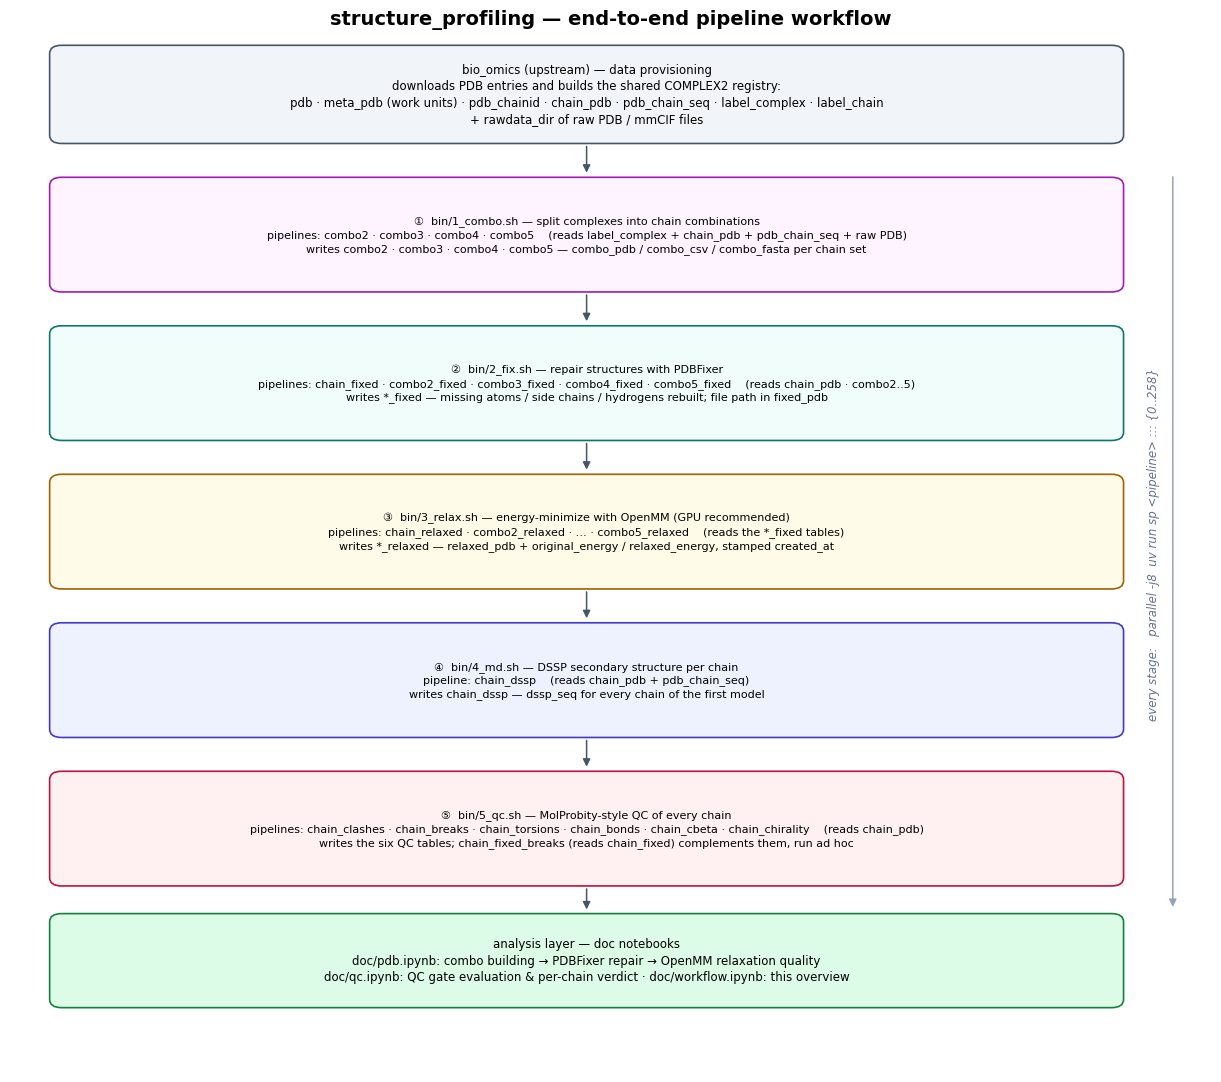

In [2]:
fig, ax = flow_fig((15.5, 13.5), ylim=12.6)
ax.set_title('structure_profiling — end-to-end pipeline workflow', fontsize=14, weight='bold')

fbox(ax, 4.8, 11.85, 8.9, 1.15,
     'bio_omics (upstream) — data provisioning\ndownloads PDB entries and builds the shared COMPLEX2 registry:\n'
     'pdb · meta_pdb (work units) · pdb_chainid · chain_pdb · pdb_chain_seq · label_complex · label_chain\n'
     '+ rawdata_dir of raw PDB / mmCIF files', '#f1f5f9', '#475569', fs=8.5)

stages = [
    (10.15, *PAL['combo'],
     '①  bin/1_combo.sh — split complexes into chain combinations\n'
     'pipelines: combo2 · combo3 · combo4 · combo5    (reads label_complex + chain_pdb + pdb_chain_seq + raw PDB)\n'
     'writes combo2 · combo3 · combo4 · combo5 — combo_pdb / combo_csv / combo_fasta per chain set'),
    (8.35, *PAL['fix'],
     '②  bin/2_fix.sh — repair structures with PDBFixer\n'
     'pipelines: chain_fixed · combo2_fixed · combo3_fixed · combo4_fixed · combo5_fixed    (reads chain_pdb · combo2..5)\n'
     'writes *_fixed — missing atoms / side chains / hydrogens rebuilt; file path in fixed_pdb'),
    (6.55, *PAL['relax'],
     '③  bin/3_relax.sh — energy-minimize with OpenMM (GPU recommended)\n'
     'pipelines: chain_relaxed · combo2_relaxed · … · combo5_relaxed    (reads the *_fixed tables)\n'
     'writes *_relaxed — relaxed_pdb + original_energy / relaxed_energy, stamped created_at'),
    (4.75, *PAL['dssp'],
     '④  bin/4_md.sh — DSSP secondary structure per chain\n'
     'pipeline: chain_dssp    (reads chain_pdb + pdb_chain_seq)\n'
     'writes chain_dssp — dssp_seq for every chain of the first model'),
    (2.95, *PAL['qc'],
     '⑤  bin/5_qc.sh — MolProbity-style QC of every chain\n'
     'pipelines: chain_clashes · chain_breaks · chain_torsions · chain_bonds · chain_cbeta · chain_chirality    (reads chain_pdb)\n'
     'writes the six QC tables; chain_fixed_breaks (reads chain_fixed) complements them, run ad hoc'),
]
for cy, fc, ec, text in stages:
    fbox(ax, 4.8, cy, 8.9, 1.35, text, fc, ec, fs=8)
farrow(ax, 4.8, 11.27, 4.8, 10.85)
for y0, y1 in [(9.47, 9.05), (7.67, 7.25), (5.87, 5.45), (4.07, 3.65)]:
    farrow(ax, 4.8, y0, 4.8, y1)

fbox(ax, 4.8, 1.35, 8.9, 1.1,
     'analysis layer — doc notebooks\n'
     'doc/pdb.ipynb: combo building → PDBFixer repair → OpenMM relaxation quality\n'
     'doc/qc.ipynb: QC gate evaluation & per-chain verdict · doc/workflow.ipynb: this overview',
     '#dcfce7', '#15803d', fs=8.5)
farrow(ax, 4.8, 2.27, 4.8, 1.92)

# side banner: the common invocation pattern of every stage
farrow(ax, 9.68, 10.9, 9.68, 1.95, color='#94a3b8')
ax.text(9.52, 6.4, 'every stage:   parallel -j8  uv run sp <pipeline> ::: {0..258}',
        rotation=90, ha='center', va='center', fontsize=8.5, color='#64748b', style='italic')

export_fig(fig, 'workflow_01_pipeline_workflow')
plt.show()

In [3]:
# pipeline registry: every sp pipeline with module, driver script, result table and live row count
SCRIPT_OF = {n: 'bin/1_combo.sh' for n in ('combo2', 'combo3', 'combo4', 'combo5')}
for n in pool:
    if n.endswith('_fixed'):
        SCRIPT_OF[n] = 'bin/2_fix.sh'
    elif n.endswith('_relaxed'):
        SCRIPT_OF[n] = 'bin/3_relax.sh'
    elif n == 'chain_dssp':
        SCRIPT_OF[n] = 'bin/4_md.sh'
    elif n.startswith('chain_'):
        SCRIPT_OF[n] = 'bin/5_qc.sh'
SCRIPT_OF['chain_fixed_breaks'] = 'ad hoc — not wired into bin/5_qc.sh'
SCRIPT_OF['test_env'] = 'diagnostic — writes no table'

rows = []
for name, mod in pool.items():
    dest = None if name == 'test_env' else name
    rows.append({
        'sp pipeline': name,
        'module (sp → python -m …)': 'src.pipelines.' + mod,
        'driver script': SCRIPT_OF.get(name, '—'),
        'result table': dest if dest else '—',
        'rows': nrows(dest),
    })
registry = pd.DataFrame(rows).sort_values(['driver script', 'sp pipeline']).reset_index(drop=True)
registry['rows'] = registry['rows'].astype('Int64')  # nullable int -> clean CSV (no 133259.0)
print(f'{len(registry)} pipelines registered in src/app/main.py; row counts queried live')
export_csv(registry, 'workflow_pipeline_registry')
registry

23 pipelines registered in src/app/main.py; row counts queried live
exported workflow_pipeline_registry.csv (23 rows) -> doc/results


,sp pipeline,module (sp → python -m …),driver script,result table,rows
0,chain_fixed_breaks,src.pipelines.qc.chain_fixed_breaks,ad hoc — not wired into bin/5_qc.sh,chain_fixed_breaks,<NA>
1,combo2,src.pipelines.pdb.combo2,bin/1_combo.sh,combo2,133259
2,combo3,src.pipelines.pdb.combo3,bin/1_combo.sh,combo3,138528
3,combo4,src.pipelines.pdb.combo4,bin/1_combo.sh,combo4,2229
4,combo5,src.pipelines.pdb.combo5,bin/1_combo.sh,combo5,4448
5,chain_fixed,src.pipelines.dynamics.chain_fixed,bin/2_fix.sh,chain_fixed,33485
6,combo2_fixed,src.pipelines.dynamics.combo2_fixed,bin/2_fix.sh,combo2_fixed,133259
7,combo3_fixed,src.pipelines.dynamics.combo3_fixed,bin/2_fix.sh,combo3_fixed,138529
8,combo4_fixed,src.pipelines.dynamics.combo4_fixed,bin/2_fix.sh,combo4_fixed,2229
9,combo5_fixed,src.pipelines.dynamics.combo5_fixed,bin/2_fix.sh,combo5_fixed,4448


## 2. QC workflow flowcharts

The two QC flowcharts (stage-5 data flow and per-chain gate evaluation) are maintained **here**,
decoupled from `doc/qc.ipynb`: this notebook defines its own matplotlib toolkit above and
queries row counts directly, so neither notebook depends on the other's cells — `qc.ipynb`
keeps its own copy of the charts.

**(a) Data flow** — how `bin/5_qc.sh` fans six QC pipelines over `chain_pdb` (plus
`chain_fixed_breaks` over `chain_fixed`) into the seven result tables of `src/sql/qc.sql`.

**(b) Gate logic** — how a single chain is judged from those tables.

exported workflow_02_qc_data_flow.tiff + workflow_02_qc_data_flow.png -> doc/results


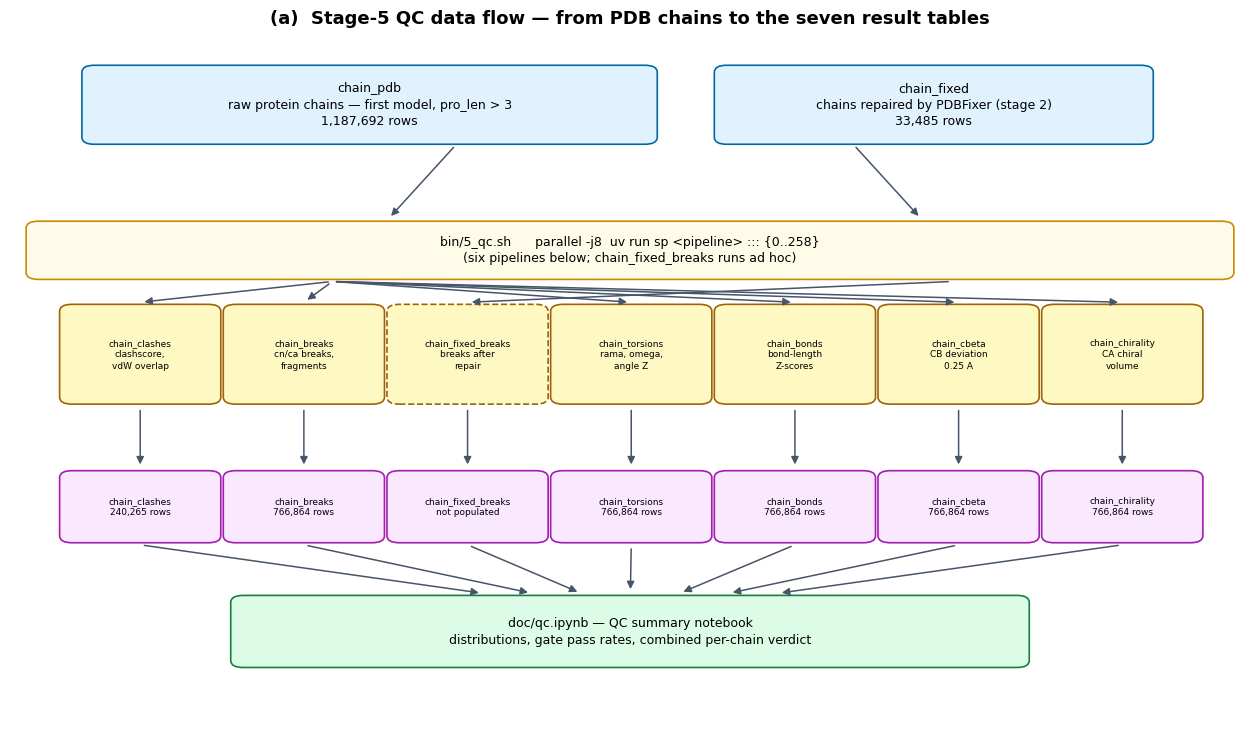

In [4]:
# (a) stage-5 QC data flow (decoupled from doc/qc.ipynb — live counts via nrows())
fig, ax = flow_fig((16, 9))
ax.set_title('(a)  Stage-5 QC data flow — from PDB chains to the seven result tables',
             fontsize=13, weight='bold')

fbox(ax, 2.9, 8.95, 4.6, 1.1,
     'chain_pdb\nraw protein chains — first model, pro_len > 3\n' + cnt(nrows('chain_pdb')),
     '#e0f2fe', '#0369a1', fs=9)
fbox(ax, 7.45, 8.95, 3.5, 1.1,
     'chain_fixed\nchains repaired by PDBFixer (stage 2)\n' + cnt(nrows('chain_fixed')),
     '#e0f2fe', '#0369a1', fs=9)
farrow(ax, 3.6, 8.38, 3.05, 7.3)
farrow(ax, 6.8, 8.38, 7.35, 7.3)

fbox(ax, 5, 6.85, 9.7, 0.8,
     'bin/5_qc.sh      parallel -j8  uv run sp <pipeline> ::: {0..258}\n'
     '(six pipelines below; chain_fixed_breaks runs ad hoc)',
     '#fefce8', '#ca8a04', fs=9)

pipelines = [
    ('chain_clashes', 'clashscore,\nvdW overlap'),
    ('chain_breaks', 'cn/ca breaks,\nfragments'),
    ('chain_fixed_breaks', 'breaks after\nrepair'),
    ('chain_torsions', 'rama, omega,\nangle Z'),
    ('chain_bonds', 'bond-length\nZ-scores'),
    ('chain_cbeta', 'CB deviation\n0.25 A'),
    ('chain_chirality', 'CA chiral\nvolume'),
]
for i, (nm, sub) in enumerate(pipelines):
    x = 1.05 + i * 1.32
    adhoc = nm == 'chain_fixed_breaks'
    fbox(ax, x, 5.35, 1.26, 1.4, nm + '\n' + sub, '#fef9c3', '#a16207',
         fs=6.5, ls='--' if adhoc else '-')
    farrow(ax, 2.6 if not adhoc else 7.6, 6.4, x, 6.1)

for i, (nm, _) in enumerate(pipelines):
    x = 1.05 + i * 1.32
    n = nrows(nm)
    missing = n == 0
    label = nm + '\n' + cnt(n) if n is not None else nm + '\nnot populated'
    fbox(ax, x, 3.15, 1.26, 1.0, label,
         '#fee2e2' if missing else '#fae8ff',
         '#b91c1c' if missing else '#a21caf',
         fs=6.5, ls='--' if missing else '-')
    farrow(ax, x, 4.6, x, 3.7)

fbox(ax, 5, 1.35, 6.4, 1.0,
     'doc/qc.ipynb — QC summary notebook\ndistributions, gate pass rates, combined per-chain verdict',
     '#dcfce7', '#15803d', fs=9)
for i in range(7):
    x = 1.05 + i * 1.32
    farrow(ax, x, 2.6, 5 + (x - 5) * 0.3, 1.9)

export_fig(fig, 'workflow_02_qc_data_flow')
plt.show()

exported workflow_03_qc_gate_evaluation.tiff + workflow_03_qc_gate_evaluation.png -> doc/results


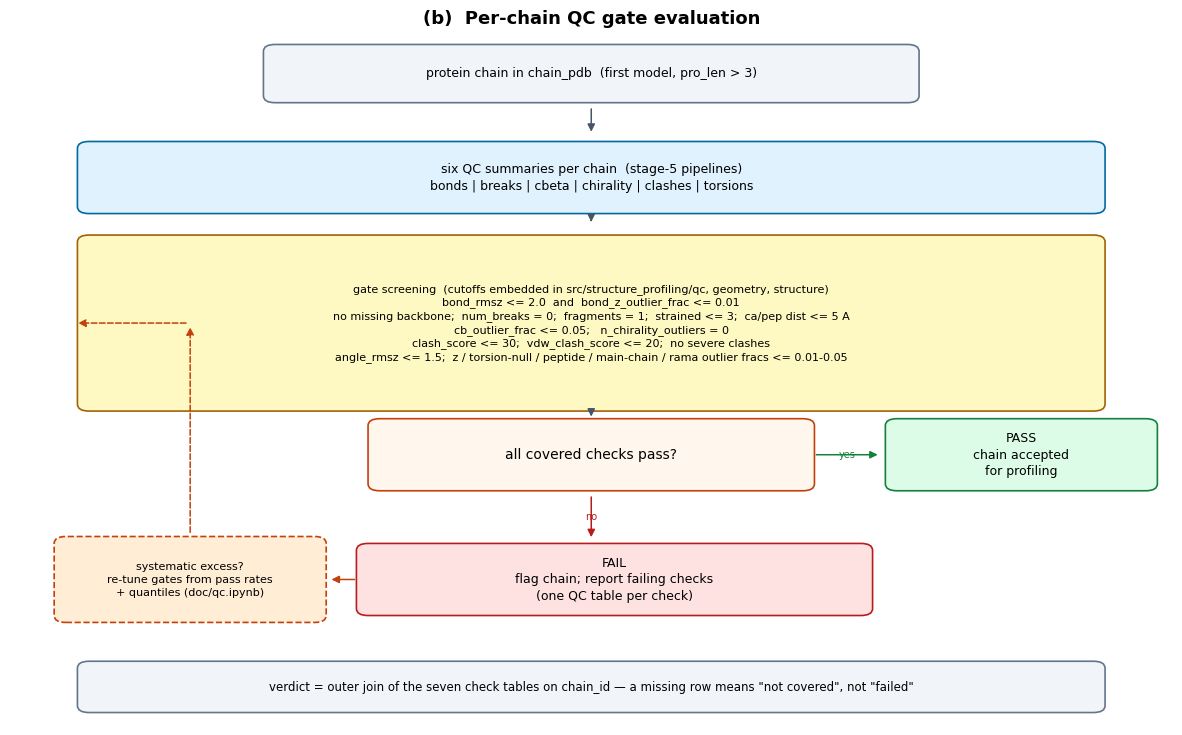

In [5]:
# (b) per-chain QC gate evaluation (decoupled from doc/qc.ipynb)
fig, ax = flow_fig((15, 9))
ax.set_title('(b)  Per-chain QC gate evaluation', fontsize=13, weight='bold')

fbox(ax, 5, 9.4, 5.6, 0.8, 'protein chain in chain_pdb  (first model, pro_len > 3)',
     '#f1f5f9', '#64748b', fs=9)
farrow(ax, 5, 8.95, 5, 8.5)
fbox(ax, 5, 7.9, 8.8, 1.0,
     'six QC summaries per chain  (stage-5 pipelines)\n'
     'bonds | breaks | cbeta | chirality | clashes | torsions',
     '#e0f2fe', '#0369a1', fs=9)
farrow(ax, 5, 7.35, 5, 7.2)
fbox(ax, 5, 5.8, 8.8, 2.5,
     'gate screening  (cutoffs embedded in src/structure_profiling/qc and structure)\n'
     'bond_rmsz <= 2.0  and  bond_z_outlier_frac <= 0.01\n'
     'no missing backbone;  num_breaks = 0;  fragments = 1;  strained <= 3;  ca/pep dist <= 5 A\n'
     'cb_outlier_frac <= 0.05;   n_chirality_outliers = 0\n'
     'clash_score <= 30;  vdw_clash_score <= 20;  no severe clashes\n'
     'angle_rmsz <= 1.5;  z / torsion-null / peptide / main-chain / rama outlier fracs <= 0.01-0.05',
     '#fef9c3', '#a16207', fs=8)
farrow(ax, 5, 4.5, 5, 4.45)

fbox(ax, 5, 3.9, 3.8, 1.0, 'all covered checks pass?', '#fff7ed', '#c2410c', fs=10)
farrow(ax, 6.9, 3.9, 7.5, 3.9, 'yes', color='#15803d')
fbox(ax, 8.7, 3.9, 2.3, 1.0, 'PASS\nchain accepted\nfor profiling', '#dcfce7', '#15803d', fs=9)
farrow(ax, 5, 3.35, 5, 2.65, 'no', color='#b91c1c')
fbox(ax, 5.2, 2.1, 4.4, 1.0, 'FAIL\nflag chain; report failing checks\n(one QC table per check)',
     '#fee2e2', '#b91c1c', fs=9)

fbox(ax, 1.55, 2.1, 2.3, 1.2, 'systematic excess?\nre-tune gates from pass rates\n+ quantiles (doc/qc.ipynb)',
     '#ffedd5', '#c2410c', fs=8, ls='--')
farrow(ax, 3.0, 2.1, 2.73, 2.1, color='#c2410c')
farrow(ax, 1.55, 2.72, 1.55, 5.8, ls='--', color='#c2410c')
farrow(ax, 1.55, 5.8, 0.55, 5.8, ls='--', color='#c2410c')

fbox(ax, 5, 0.55, 8.8, 0.7,
     'verdict = outer join of the seven check tables on chain_id — a missing row means "not covered", not "failed"',
     '#f1f5f9', '#64748b', fs=8.5)
export_fig(fig, 'workflow_03_qc_gate_evaluation')
plt.show()

## 3. SQL tables & relationships

Three ER-style panels over the `COMPLEX2` database (MySQL/MariaDB). Conventions:

- **`tbox` cards** show the table name, its keys and characteristic columns —
  `PK` primary key, `UK` unique key, `FK` foreign key.
- **Solid arrows** are real `FOREIGN KEY … REFERENCES pdb(pdb_id) ON DELETE CASCADE`
  constraints; every result table carries one, so deleting a `pdb` row cascades everywhere.
- **Dashed arrows** are logical lineage — the producer→consumer flow written by the pipelines.
- The italic footer of each card is the **live row count** (`SELECT COUNT(*)`, `n/a` when the DB is unreachable).

| panel | scope | schema source |
|-------|-------|---------------|
| (c) | core registry shared with bio_omics: `pdb`, `meta_pdb`, `pdb_chainid`, `chain_pdb`, `pdb_chain_seq`, `label_complex`, `label_chain`, `meta_execute` | upstream bio_omics |
| (d) | structure products: `chain_dssp`, `chain_fixed`, `chain_relaxed`, `combo2..5_fixed`, `combo2..5_relaxed` | `src/sql/pdb.sql`, `src/sql/simulate.sql` |
| (e) | QC tables: `chain_clashes`, `chain_breaks`, `chain_fixed_breaks`, `chain_torsions`, `chain_bonds`, `chain_cbeta`, `chain_chirality` | `src/sql/qc.sql` |

exported workflow_04_er_core_registry.tiff + workflow_04_er_core_registry.png -> doc/results


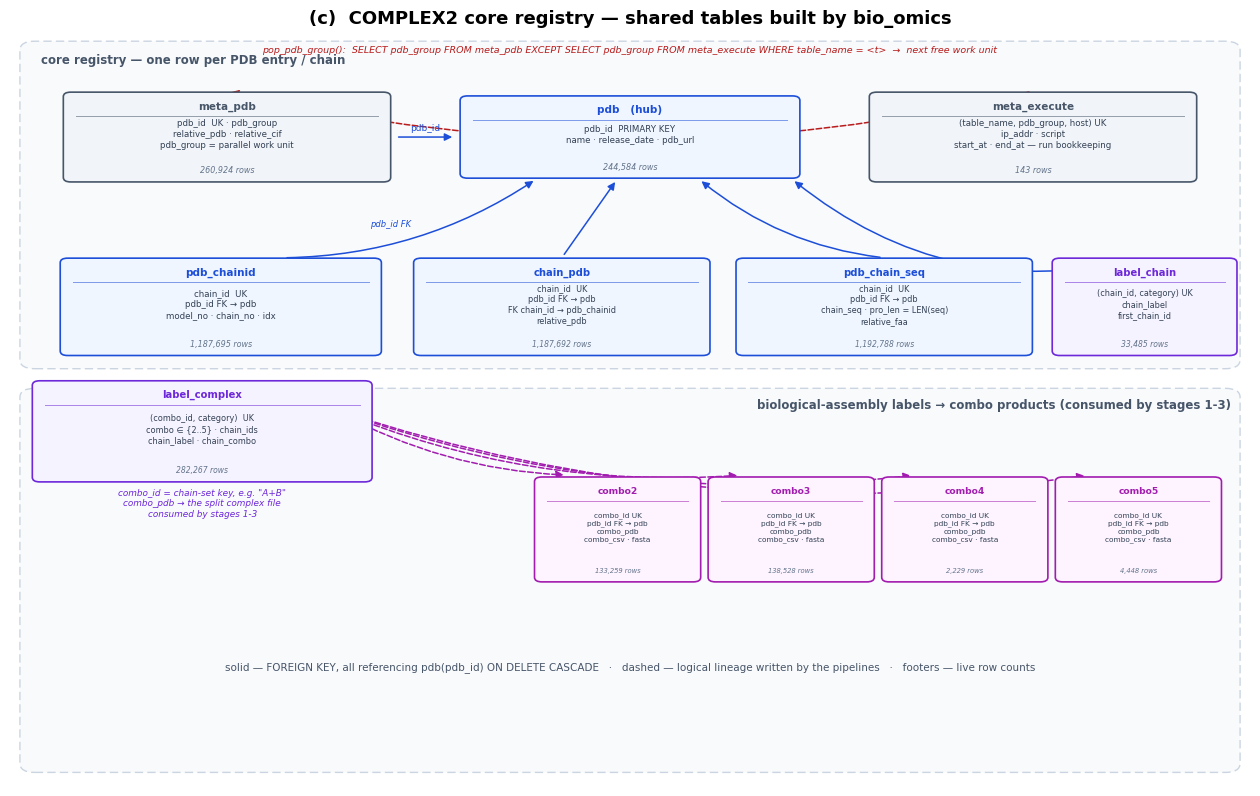

In [6]:
# (c) core registry — shared tables built by bio_omics
fig, ax = flow_fig((16, 9.8))
ax.set_title('(c)  COMPLEX2 core registry — shared tables built by bio_omics',
             fontsize=13, weight='bold')

fzone(ax, 0.1, 5.55, 9.8, 4.3, 'core registry — one row per PDB entry / chain')
fzone(ax, 0.1, 0.2, 9.8, 5.05, '')
ax.text(9.85, 5.06, 'biological-assembly labels → combo products (consumed by stages 1-3)',
        ha='right', va='center', fontsize=8.5, weight='bold', color='#475569', zorder=1)

tbox(ax, 1.75, 8.6, 2.6, 1.15, 'meta_pdb',
     'pdb_id  UK · pdb_group\nrelative_pdb · relative_cif\npdb_group = parallel work unit',
     *PAL['meta'], count=nrows('meta_pdb'))
tbox(ax, 5.0, 8.6, 2.7, 1.05, 'pdb   (hub)',
     'pdb_id  PRIMARY KEY\nname · release_date · pdb_url',
     *PAL['core'], count=nrows('pdb'))
tbox(ax, 8.25, 8.6, 2.6, 1.15, 'meta_execute',
     '(table_name, pdb_group, host) UK\nip_addr · script\nstart_at · end_at — run bookkeeping',
     *PAL['meta'], count=nrows('meta_execute'))
farrow(ax, 3.1, 8.6, 3.6, 8.6, 'pdb_id', color='#1d4ed8', fs=6.5, dy=0.12)

tbox(ax, 1.7, 6.35, 2.55, 1.25, 'pdb_chainid',
     'chain_id  UK\npdb_id FK → pdb\nmodel_no · chain_no · idx',
     *PAL['core'], count=nrows('pdb_chainid'))
tbox(ax, 4.45, 6.35, 2.35, 1.25, 'chain_pdb',
     'chain_id  UK\npdb_id FK → pdb\nFK chain_id → pdb_chainid\nrelative_pdb',
     *PAL['core'], fs=5.9, count=nrows('chain_pdb'))
tbox(ax, 7.05, 6.35, 2.35, 1.25, 'pdb_chain_seq',
     'chain_id  UK\npdb_id FK → pdb\nchain_seq · pro_len = LEN(seq)\nrelative_faa',
     *PAL['core'], fs=5.9, count=nrows('pdb_chain_seq'))
tbox(ax, 9.15, 6.35, 1.45, 1.25, 'label_chain',
     '(chain_id, category) UK\nchain_label\nfirst_chain_id',
     *PAL['label'], fs=5.9, count=nrows('label_chain'))
for x0, x1, rad in [(2.2, 4.25, 0.15), (4.45, 4.9, 0.0), (7.05, 5.55, -0.15), (9.15, 6.3, -0.25)]:
    farrow(ax, x0, 7.0, x1, 8.05, color='#1d4ed8', rad=rad)
ax.text(2.9, 7.42, 'pdb_id FK', fontsize=6, color='#1d4ed8', style='italic')

# work queue: pop_pdb_group() = meta_pdb EXCEPT meta_execute
farrow(ax, 8.25, 9.21, 1.75, 9.21, ls='--', color='#b91c1c', rad=-0.12)
ax.text(5.0, 9.72, 'pop_pdb_group():  SELECT pdb_group FROM meta_pdb EXCEPT '
        'SELECT pdb_group FROM meta_execute WHERE table_name = <t>  →  next free work unit',
        ha='center', fontsize=6.8, color='#b91c1c', style='italic')

tbox(ax, 1.55, 4.7, 2.7, 1.3, 'label_complex',
     '(combo_id, category)  UK\ncombo ∈ {2..5} · chain_ids\nchain_label · chain_combo',
     *PAL['label'], fs=5.9, count=nrows('label_complex'))
ax.text(1.55, 3.75, 'combo_id = chain-set key, e.g. "A+B"\ncombo_pdb → the split complex file\n'
        'consumed by stages 1-3', ha='center', va='center', fontsize=6.4,
        color='#6d28d9', style='italic')

combos = [('combo2', 4.9), ('combo3', 6.3), ('combo4', 7.7), ('combo5', 9.1)]
for nm, x in combos:
    tbox(ax, x, 3.4, 1.3, 1.35, nm,
         'combo_id UK\npdb_id FK → pdb\ncombo_pdb\ncombo_csv · fasta',
         *PAL['combo'], fs=5.3, count=nrows(nm))
    farrow(ax, 2.6, 5.0, x - 0.4, 4.12, ls='--', color='#a21caf', rad=0.12)
# label_complex / label_chain also carry FK pdb_id → pdb (see legend)

ax.text(5.0, 1.55, 'solid — FOREIGN KEY, all referencing pdb(pdb_id) ON DELETE CASCADE   ·   '
        'dashed — logical lineage written by the pipelines   ·   footers — live row counts',
        ha='center', fontsize=7.5, color='#475569')
export_fig(fig, 'workflow_04_er_core_registry')
plt.show()

exported workflow_05_er_structure_products.tiff + workflow_05_er_structure_products.png -> doc/results


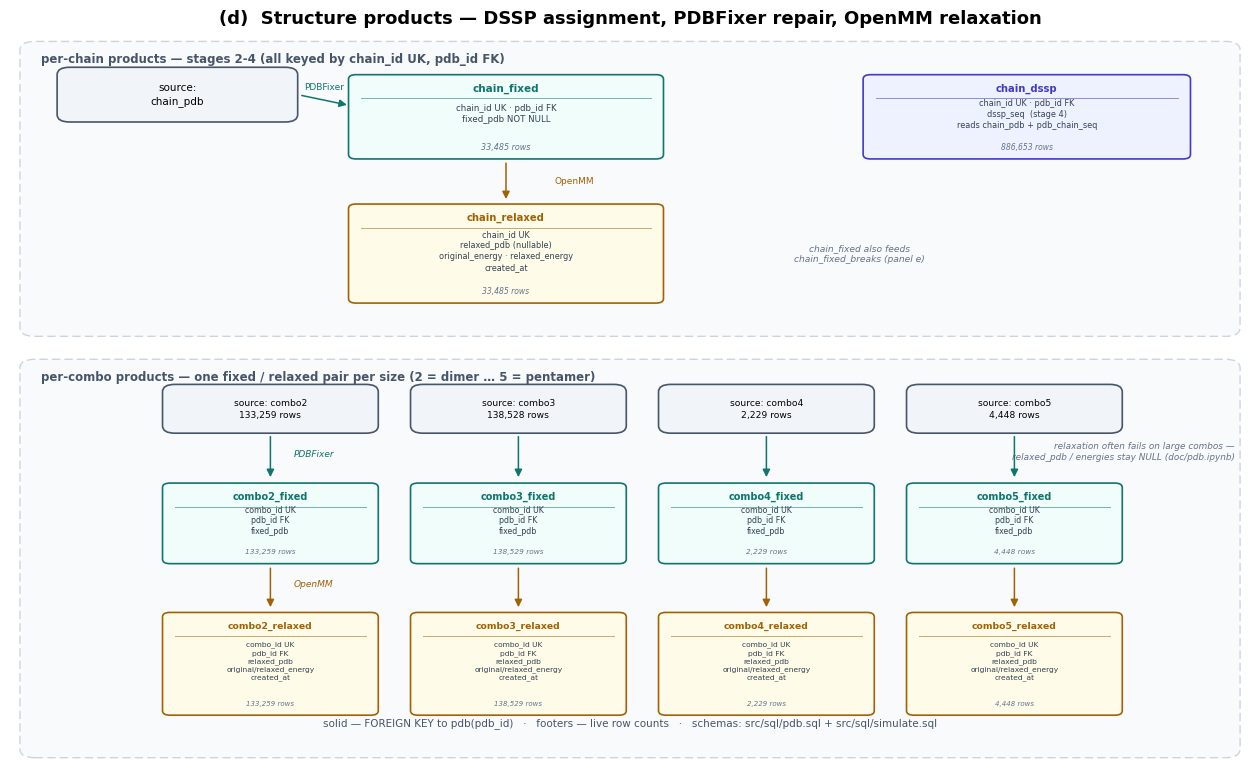

In [7]:
# (d) structure products — dssp / fixed / relaxed, per chain and per combo size
fig, ax = flow_fig((16, 9.6))
ax.set_title('(d)  Structure products — DSSP assignment, PDBFixer repair, OpenMM relaxation',
             fontsize=13, weight='bold')

fzone(ax, 0.1, 5.9, 9.8, 3.95, 'per-chain products — stages 2-4 (all keyed by chain_id UK, pdb_id FK)')
fzone(ax, 0.1, 0.2, 9.8, 5.35,
      'per-combo products — one fixed / relaxed pair per size (2 = dimer … 5 = pentamer)')

fbox(ax, 1.35, 9.15, 1.9, 0.7, 'source:\nchain_pdb', *PAL['meta'], fs=7.5)
tbox(ax, 4.0, 8.85, 2.5, 1.1, 'chain_fixed',
     'chain_id UK · pdb_id FK\nfixed_pdb NOT NULL',
     *PAL['fix'], count=nrows('chain_fixed'))
tbox(ax, 4.0, 7.0, 2.5, 1.3, 'chain_relaxed',
     'chain_id UK\nrelaxed_pdb (nullable)\noriginal_energy · relaxed_energy\ncreated_at',
     *PAL['relax'], fs=5.9, count=nrows('chain_relaxed'))
farrow(ax, 2.32, 9.15, 2.75, 9.0, 'PDBFixer', color='#0f766e', fs=6.5, dy=0.18)
farrow(ax, 4.0, 8.28, 4.0, 7.68, 'OpenMM', color='#a16207', fs=6.5, dx=0.55)

tbox(ax, 8.2, 8.85, 2.6, 1.1, 'chain_dssp',
     'chain_id UK · pdb_id FK\ndssp_seq  (stage 4)\nreads chain_pdb + pdb_chain_seq',
     *PAL['dssp'], fs=5.9, count=nrows('chain_dssp'))
ax.text(6.85, 7.0, 'chain_fixed also feeds\nchain_fixed_breaks (panel e)',
        ha='center', va='center', fontsize=6.6, color='#64748b', style='italic')

srcs = [('combo2', 2.1), ('combo3', 4.1), ('combo4', 6.1), ('combo5', 8.1)]
for nm, x in srcs:
    fbox(ax, x, 4.9, 1.7, 0.62, f'source: {nm}\n' + cnt(nrows(nm)), *PAL['meta'], fs=6.6)
    tbox(ax, x, 3.35, 1.7, 1.05, nm + '_fixed',
         'combo_id UK\npdb_id FK\nfixed_pdb',
         *PAL['fix'], fs=5.7, count=nrows(nm + '_fixed'))
    tbox(ax, x, 1.45, 1.7, 1.35, nm + '_relaxed',
         'combo_id UK\npdb_id FK\nrelaxed_pdb\noriginal/relaxed_energy\ncreated_at',
         *PAL['relax'], fs=5.4, count=nrows(nm + '_relaxed'))
    farrow(ax, x, 4.58, x, 3.92, color='#0f766e')
    farrow(ax, x, 2.8, x, 2.16, color='#a16207')
ax.text(2.45, 4.25, 'PDBFixer', fontsize=6.5, color='#0f766e', style='italic', ha='center')
ax.text(2.45, 2.5, 'OpenMM', fontsize=6.5, color='#a16207', style='italic', ha='center')
ax.text(9.88, 4.32, 'relaxation often fails on large combos —\nrelaxed_pdb / energies stay NULL (doc/pdb.ipynb)',
        ha='right', va='center', fontsize=6.4, color='#64748b', style='italic')

ax.text(5.0, 0.62, 'solid — FOREIGN KEY to pdb(pdb_id)   ·   footers — live row counts   ·   '
        'schemas: src/sql/pdb.sql + src/sql/simulate.sql',
        ha='center', fontsize=7.5, color='#475569')
export_fig(fig, 'workflow_05_er_structure_products')
plt.show()

exported workflow_06_er_qc_tables.tiff + workflow_06_er_qc_tables.png -> doc/results


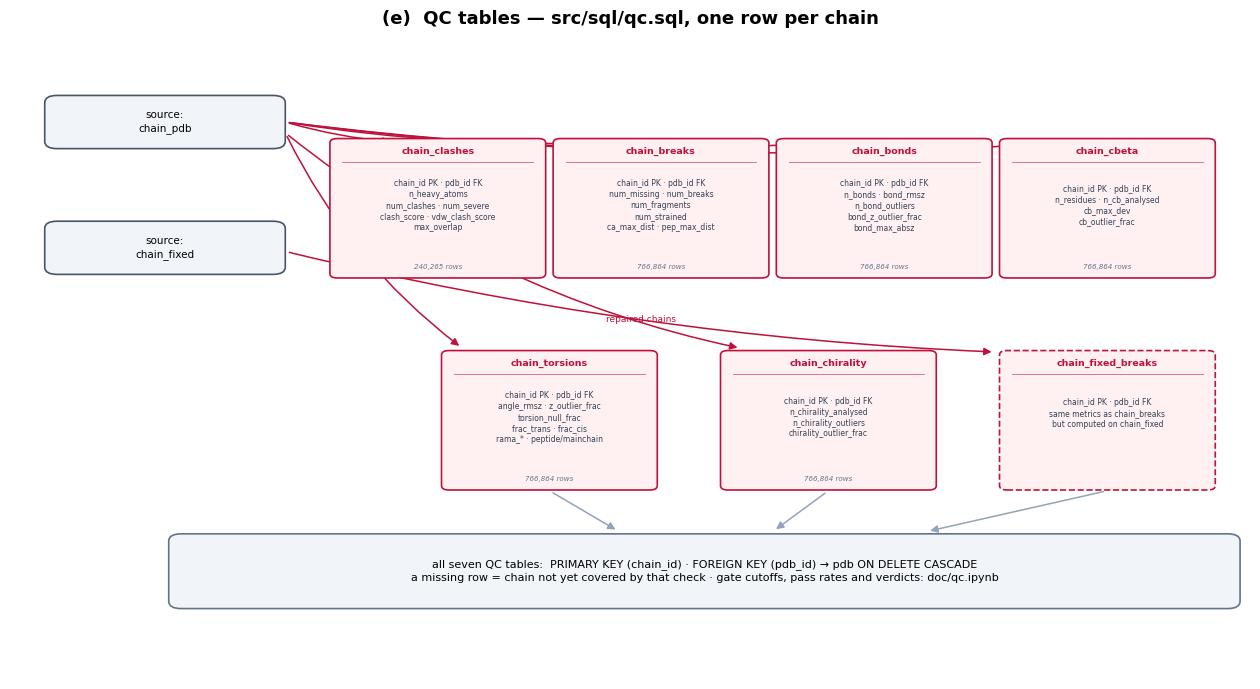

In [8]:
# (e) QC tables — one row per chain, fanned out from chain_pdb / chain_fixed
fig, ax = flow_fig((16, 8.4), ylim=9)
ax.set_title('(e)  QC tables — src/sql/qc.sql, one row per chain', fontsize=13, weight='bold')

fbox(ax, 1.25, 7.75, 1.9, 0.7, 'source:\nchain_pdb', *PAL['meta'], fs=7.5)
fbox(ax, 1.25, 6.0, 1.9, 0.7, 'source:\nchain_fixed', *PAL['meta'], fs=7.5)

row1 = [
    (3.45, 'chain_clashes',
     'chain_id PK · pdb_id FK\nn_heavy_atoms\nnum_clashes · num_severe\nclash_score · vdw_clash_score\nmax_overlap'),
    (5.25, 'chain_breaks',
     'chain_id PK · pdb_id FK\nnum_missing · num_breaks\nnum_fragments\nnum_strained\nca_max_dist · pep_max_dist'),
    (7.05, 'chain_bonds',
     'chain_id PK · pdb_id FK\nn_bonds · bond_rmsz\nn_bond_outliers\nbond_z_outlier_frac\nbond_max_absz'),
    (8.85, 'chain_cbeta',
     'chain_id PK · pdb_id FK\nn_residues · n_cb_analysed\ncb_max_dev\ncb_outlier_frac'),
]
row2 = [
    (4.35, 'chain_torsions',
     'chain_id PK · pdb_id FK\nangle_rmsz · z_outlier_frac\ntorsion_null_frac\nfrac_trans · frac_cis\nrama_* · peptide/mainchain'),
    (6.6, 'chain_chirality',
     'chain_id PK · pdb_id FK\nn_chirality_analysed\nn_chirality_outliers\nchirality_outlier_frac'),
    (8.85, 'chain_fixed_breaks',
     'chain_id PK · pdb_id FK\nsame metrics as chain_breaks\nbut computed on chain_fixed'),
]
for x, nm, cols in row1:
    tbox(ax, x, 6.55, 1.7, 1.9, nm, cols, *PAL['qc'], fs=5.5, count=nrows(nm))
    farrow(ax, 2.22, 7.75, x - 0.35, 7.47, color='#be123c', rad=0.05)
for x, nm, cols in row2:
    adhoc = nm == 'chain_fixed_breaks'
    tbox(ax, x, 3.6, 1.7, 1.9, nm, cols, *PAL['qc'], fs=5.5,
         count=nrows(nm), ls='--' if adhoc else '-')
    if not adhoc:
        farrow(ax, 2.22, 7.6, x - 0.7, 4.6, color='#be123c', rad=0.12)
farrow(ax, 2.22, 5.95, 7.95, 4.55, 'repaired chains', color='#be123c',
       fs=6.5, rad=0.05, dy=-0.25)

fbox(ax, 5.6, 1.5, 8.6, 1.0,
     'all seven QC tables:  PRIMARY KEY (chain_id) · FOREIGN KEY (pdb_id) → pdb ON DELETE CASCADE\n'
     'a missing row = chain not yet covered by that check · gate cutoffs, pass rates and verdicts: doc/qc.ipynb',
     '#f1f5f9', '#64748b', fs=8)
for x in (4.35, 6.6, 8.85):
    farrow(ax, x, 2.62, 5.6 + (x - 5.6) * 0.55, 2.05, color='#94a3b8')
export_fig(fig, 'workflow_06_er_qc_tables')
plt.show()

## 4. Execution mechanics — one `sp` run

`sp <pipeline> [pdb_group]` (console script → `src/app/main.py`) is the only entry point the
driver scripts use. Two ways to pick the work unit:

- **explicit** — `parallel -j8 sp <pipeline> ::: {0..258}` in `bin/*.sh` passes the group; no booking happens, workers simply start;
- **auto** — no argument: the lowest group present in `meta_pdb` but absent from `meta_execute` for that table is *popped* and booked by inserting a `meta_execute` row, so concurrent hosts never take the same unit.

Work retrieval is **incremental**: candidates of the group are filtered with
`NOT IN / NOT EXISTS` against the destination table, so a re-run only computes rows that are
still missing. When no group is left, the process exits cleanly with status 0.

exported workflow_07_sp_run_anatomy.tiff + workflow_07_sp_run_anatomy.png -> doc/results


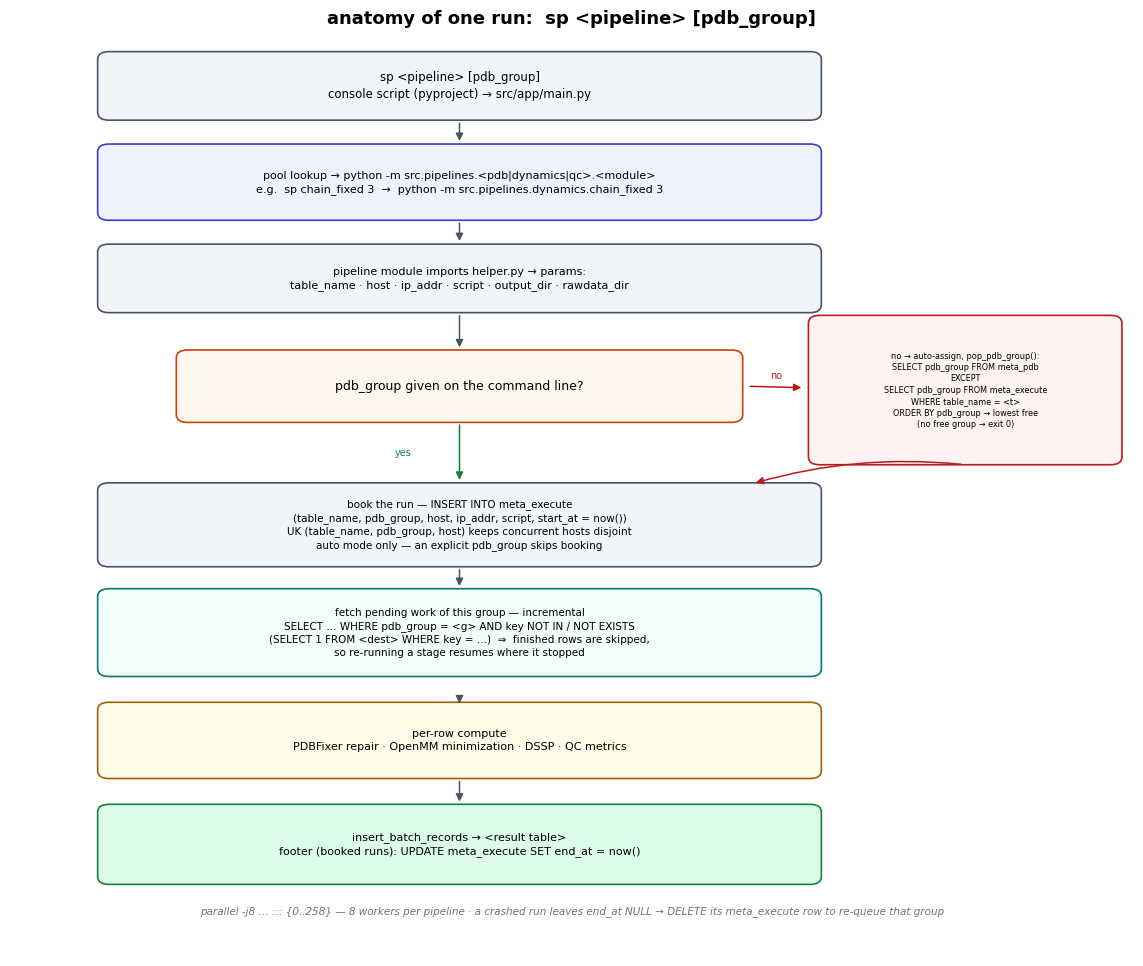

In [9]:
fig, ax = flow_fig((14.5, 12), ylim=12)
ax.set_title('anatomy of one run:  sp <pipeline> [pdb_group]', fontsize=13, weight='bold')

fbox(ax, 4.0, 11.3, 6.4, 0.85,
     'sp <pipeline> [pdb_group]\nconsole script (pyproject) → src/app/main.py',
     '#f1f5f9', '#475569', fs=8.5)
farrow(ax, 4.0, 10.87, 4.0, 10.53)
fbox(ax, 4.0, 10.05, 6.4, 0.95,
     'pool lookup → python -m src.pipelines.<pdb|dynamics|qc>.<module>\n'
     'e.g.  sp chain_fixed 3  →  python -m src.pipelines.dynamics.chain_fixed 3',
     '#eef2ff', '#4338ca', fs=8)
farrow(ax, 4.0, 9.57, 4.0, 9.23)
fbox(ax, 4.0, 8.8, 6.4, 0.85,
     'pipeline module imports helper.py → params:\n'
     'table_name · host · ip_addr · script · output_dir · rawdata_dir',
     '#f1f5f9', '#475569', fs=8)
farrow(ax, 4.0, 8.37, 4.0, 7.85)

fbox(ax, 4.0, 7.4, 5.0, 0.9, 'pdb_group given on the command line?',
     '#fff7ed', '#c2410c', fs=9)
fbox(ax, 8.5, 7.35, 2.75, 1.9,
     'no → auto-assign, pop_pdb_group():\nSELECT pdb_group FROM meta_pdb\nEXCEPT\n'
     'SELECT pdb_group FROM meta_execute\nWHERE table_name = <t>\n'
     'ORDER BY pdb_group → lowest free\n(no free group → exit 0)',
     '#fef2f2', '#b91c1c', fs=5.9)
farrow(ax, 6.55, 7.4, 7.08, 7.38, 'no', color='#b91c1c', dy=0.15)

fbox(ax, 4.0, 5.6, 6.4, 1.05,
     'book the run — INSERT INTO meta_execute\n'
     '(table_name, pdb_group, host, ip_addr, script, start_at = now())\n'
     'UK (table_name, pdb_group, host) keeps concurrent hosts disjoint\n'
     'auto mode only — an explicit pdb_group skips booking',
     '#f1f5f9', '#475569', fs=7.5)
farrow(ax, 4.0, 6.95, 4.0, 6.13, 'yes', color='#15803d', dx=-0.5)
farrow(ax, 8.5, 6.38, 6.6, 6.13, color='#b91c1c', rad=0.1)

fbox(ax, 4.0, 4.2, 6.4, 1.1,
     'fetch pending work of this group — incremental\n'
     'SELECT … WHERE pdb_group = <g> AND key NOT IN / NOT EXISTS\n'
     '(SELECT 1 FROM <dest> WHERE key = …)  ⇒  finished rows are skipped,\n'
     'so re-running a stage resumes where it stopped',
     '#f0fdfa', '#0f766e', fs=7.5)
farrow(ax, 4.0, 5.07, 4.0, 4.75)
fbox(ax, 4.0, 2.8, 6.4, 0.95,
     'per-row compute\nPDBFixer repair · OpenMM minimization · DSSP · QC metrics',
     '#fefce8', '#a16207', fs=8)
farrow(ax, 4.0, 3.32, 4.0, 3.28)
fbox(ax, 4.0, 1.45, 6.4, 1.0,
     'insert_batch_records → <result table>\n'
     'footer (booked runs): UPDATE meta_execute SET end_at = now()',
     '#dcfce7', '#15803d', fs=8)
farrow(ax, 4.0, 2.32, 4.0, 1.95)

ax.text(5.0, 0.55,
        'parallel -j8 … ::: {0..258} — 8 workers per pipeline · a crashed run leaves end_at NULL '
        '→ DELETE its meta_execute row to re-queue that group',
        ha='center', fontsize=7.5, color='#64748b', style='italic')
export_fig(fig, 'workflow_07_sp_run_anatomy')
plt.show()

## 5. Takeaways

- **Five stages, one entry point** — `bin/1_combo.sh → 5_qc.sh` wrap `uv run sp <pipeline>`;
  the pipeline registry in `src/app/main.py` is the single source of truth (table above).
- **Everything is resumable** — result tables are the progress ledger: the `NOT IN / NOT EXISTS`
  guards recompute only missing rows, so re-running any `bin/*.sh` is safe and cheap.
- **`pdb_group` is the unit of parallelism** — 259 groups defined in `meta_pdb`; explicit groups
  drive `parallel -j8`, auto mode books the lowest free group via `meta_pdb EXCEPT meta_execute`
  and stamps `meta_execute.start_at / end_at`. A crashed booked run (`end_at` NULL) must be
  deleted from `meta_execute` to be re-queued.
- **One relational hub** — every table hangs off `pdb(pdb_id)` with `ON DELETE CASCADE`
  (panel c); chains are keyed by `chain_id`, chain sets by `combo_id` (panels d, e).
- **Exports** — per the `doc/*.ipynb` convention, all diagrams land in `doc/results/` as
  `*.tiff` (300 dpi) + small `*.png`, and all tables as `*.csv` (cell below prints the manifest).
- **Related notebooks** — `doc/pdb.ipynb` (combo → fix → relax quality), `doc/qc.ipynb`
  (QC gates and per-chain verdicts); this notebook holds the workflow/ER diagrams so the
  three stay decoupled.

In [10]:
# exports — doc/*.ipynb convention: diagrams -> *.tiff + small *.png, tables -> *.csv
counts = pd.DataFrame([{'table': t, 'rows': _NROWS[t]} for t in sorted(_NROWS)])
counts['rows'] = counts['rows'].astype('Int64')
export_csv(counts, 'workflow_table_row_counts')

print('manifest of doc/results/:')
for p in sorted(RESULTS_DIR.iterdir()):
    print(f'  {p.name:<42s} {p.stat().st_size / 1024:9.1f} KB')

exported workflow_table_row_counts.csv (30 rows) -> doc/results
manifest of doc/results/:
  workflow_01_pipeline_workflow.png              143.3 KB
  workflow_01_pipeline_workflow.tiff            1254.8 KB
  workflow_02_qc_data_flow.png                   101.9 KB
  workflow_02_qc_data_flow.tiff                  841.4 KB
  workflow_03_qc_gate_evaluation.png              89.7 KB
  workflow_03_qc_gate_evaluation.tiff            817.1 KB
  workflow_04_er_core_registry.png               130.5 KB
  workflow_04_er_core_registry.tiff             1225.3 KB
  workflow_05_er_structure_products.png          101.3 KB
  workflow_05_er_structure_products.tiff        1159.7 KB
  workflow_06_er_qc_tables.png                    89.4 KB
  workflow_06_er_qc_tables.tiff                  777.9 KB
  workflow_07_sp_run_anatomy.png                 116.7 KB
  workflow_07_sp_run_anatomy.tiff               1014.2 KB
  workflow_pipeline_registry.csv                   1.8 KB
  workflow_table_row_counts.csv         